# Heart Disease 

### Life cycle of Machine learning Project

- understanding the problem Statement
- Collect some information form data
- Data Checks to perform
- Exploratory data analysis
- Data pre-processing 
- Model Training 
- Choose best Model

## 1. Problem Statement

- Analyze the provided Heart Disease dataset, perform Exploratory Data Analysis (EDA), preprocess the data, and develop a Machine Learning model to predict the presence of heart disease.

### Import data and requied packages

In [2]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("heart.csv")

In [4]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [5]:
df.shape

(303, 14)

### 2. Collect some information from data

- It have 303 rows ans 14 columns.
- there are some columns for predict disease (some report of a person) like -> age, gender, cp (chest pain) , trestbps(resting blood pressure) , chol(cholesterol) , fbs(fasting blood sugar) , restecg(resting electrocardiographic) , thalach (maximun heart rate) , exang (exercise-induced angina) , oldpeak(ST Depression) , slope(Slope of Peak Exercise ST Segment) ,ca(Number of Major Vessels), thal(Thalassemia Test Result)
- target -> there 1 (heart disease present) and 0 (heart disease not present)


## 3. check data to perform

#### 3.1 check missing values

In [6]:
df.isnull().sum()


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

- there are no missing value

#### 3.2 Check the duplicates

In [7]:
df.duplicated().sum()

np.int64(1)

#### there is only one duplicate

In [8]:
df=df.drop_duplicates()

#### 3.3 check Datatype

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


#### 3.4 check the unique values in each columns

In [10]:
df.nunique()

age          41
sex           2
cp            4
trestbps     49
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            5
thal          4
target        2
dtype: int64

##### divide column base on nunique values in column 

- if column have less than 10 nunique value then conferm that this is a make from categorical feature

In [11]:
non_categorical_feature=[feature for feature in df.columns if df[feature].nunique()>10 ]
categorical_feature=[feature for feature in df.columns if df[feature].nunique()<10 ]

### 3.5 Staticties of the data 

In [12]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


#### insights

- this data have only btw age 29 to 77 person
- highest chol(cholesterol) is 564 in this data
- almost 75% person not have fbs (fasting blood sugar)

In [18]:
df.to_csv("cleandata_heart.csv")

## 4. Perform Exploratory Data Analysis (EDA)

In [13]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


- see the non categorical feature 

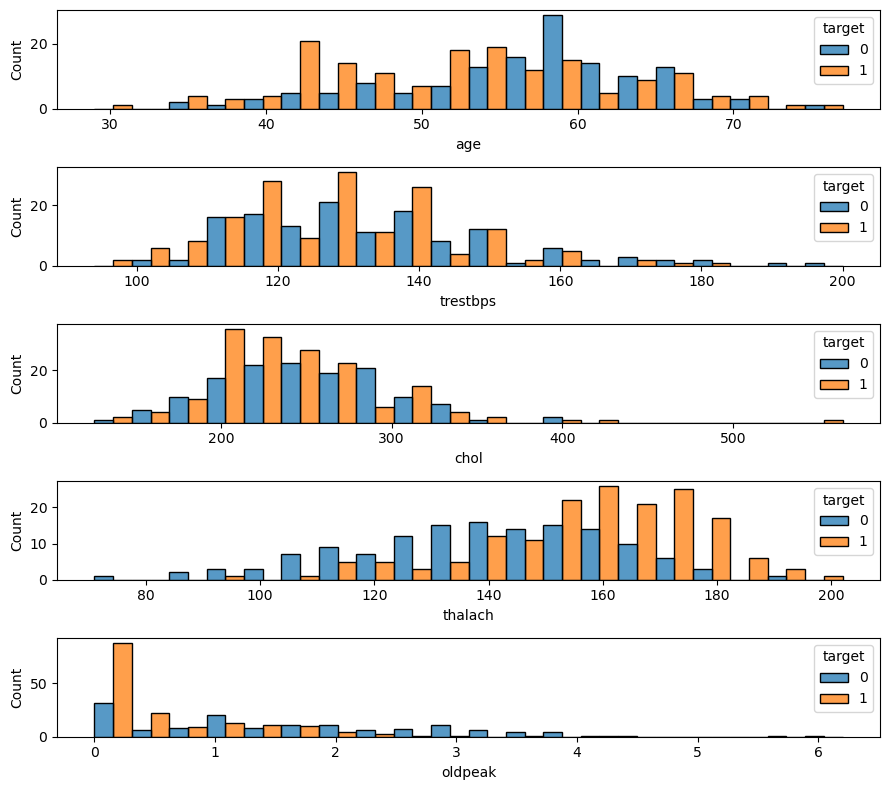

In [14]:

fig, axes= plt.subplots(5,1,figsize=(9,8))
axes=axes.flatten()
for i, col in enumerate(non_categorical_feature):
    sns.histplot(ax=axes[i],data=df,x=col,hue="target",bins=20,multiple="dodge")

plt.tight_layout()

### insights

- there thalach increase the chance of heart disease 
- oldpeak if btw 0 to 1 than high chance of heart disease

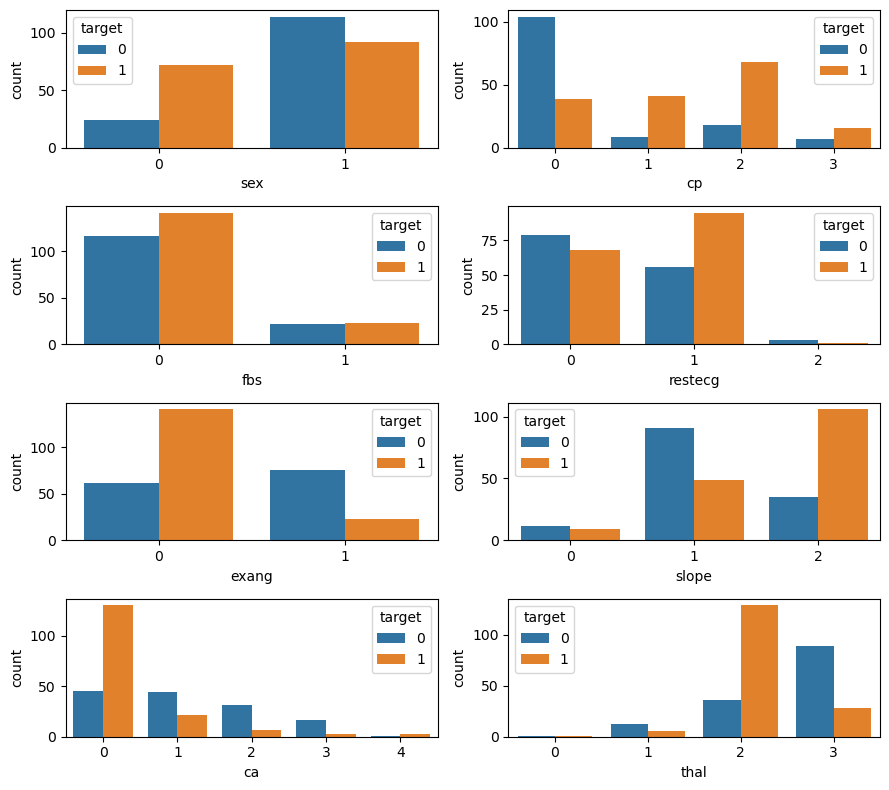

In [15]:
fig,axes=plt.subplots(4,2,figsize=(9,8))
axes=axes.flatten()

for i,col in enumerate(categorical_feature):
    if col!="target":
        sns.countplot(ax=axes[i],data=df,x=col,hue="target")

plt.tight_layout()

#### insights
- if 1 represent to male than male have disease compare than female verse-vice.
- there this people have restecg 1 they have high chance of disease.
- there thal on 2 these have chance of disease.
- there ca on 0 these have chance of disease.



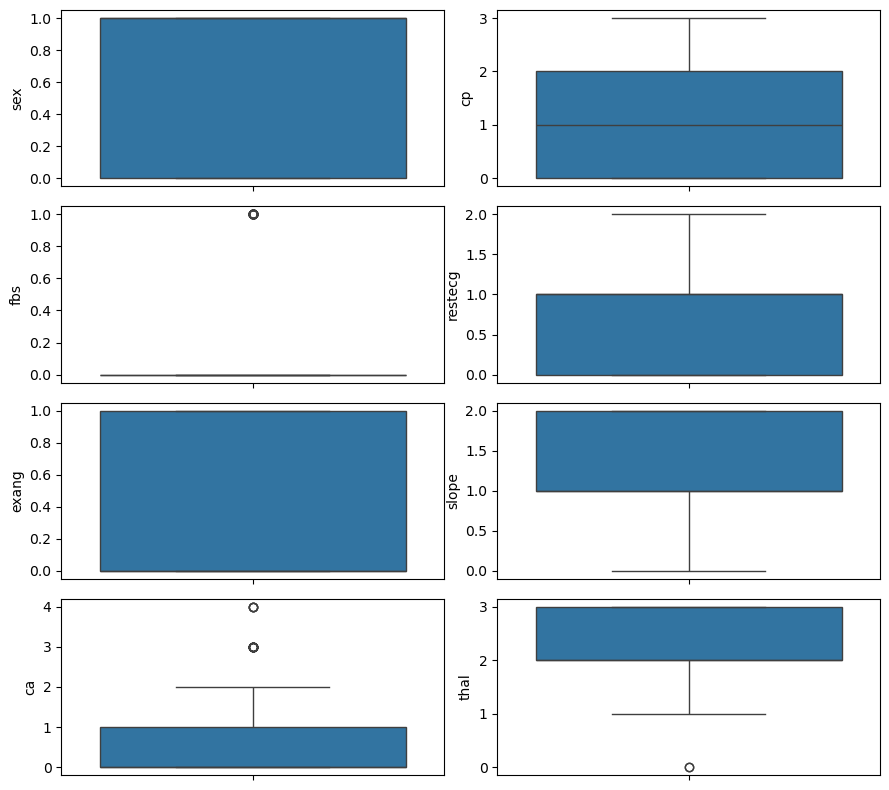

In [16]:
fig,axes=plt.subplots(4,2,figsize=(9,8))
axes=axes.flatten()

for i,col in enumerate(categorical_feature):
    if col!="target":
        sns.boxplot(ax=axes[i],data=df,y=col)

plt.tight_layout()

- there are not large outlier in categorical feature

- correlation heatmap

<Axes: >

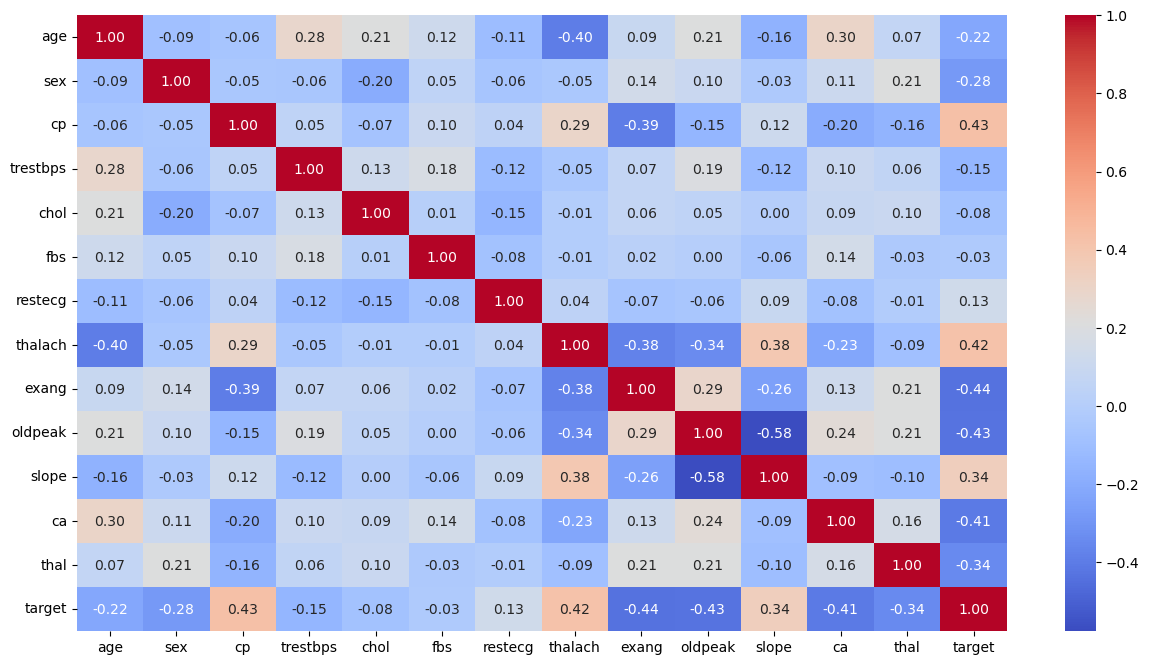

In [31]:
corr_matrix=df.corr()
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

## 5. Model training

- convert all data into X and y , there X have input feature and y have output feature.

In [19]:
X=df.drop("target",axis=1)
y=df["target"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

- Do X-train and text data scale for some model

In [32]:
from sklearn.preprocessing import StandardScaler
#Scaling
scaler=StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

- logistic Regression

In [61]:
from sklearn.linear_model import LogisticRegression

linear_reg=LogisticRegression()

linear_reg.fit(X_train_scaled,y_train)

y_pred=linear_reg.predict(X_test_scaled)
from sklearn.metrics import precision_score ,accuracy_score, recall_score, f1_score,confusion_matrix
print("logistic regression model")
print("precision: ",precision_score(y_test,y_pred))
print("accuracy: ",accuracy_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))
print("confusion matrix: ",confusion_matrix(y_test,y_pred))


logistic regression model
precision:  0.8387096774193549
accuracy:  0.819672131147541
recall_score:  0.8125
f1_score:  0.8253968253968254
confusion matrix:  [[24  5]
 [ 6 26]]


- naive bayes

In [57]:
from sklearn.naive_bayes import GaussianNB

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)

y_pred = gnb_model.predict(X_test_scaled)

#Evaluate
from sklearn.metrics import precision_score ,accuracy_score, recall_score, f1_score,confusion_matrix
print("naive bayes model")
print("precision: ",precision_score(y_test,y_pred))
print("accuracy: ",accuracy_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))
print("confusion matrix: ",confusion_matrix(y_test,y_pred))

naive bayes model
precision:  0.9310344827586207
accuracy:  0.8852459016393442
recall_score:  0.84375
f1_score:  0.8852459016393442
confusion matrix:  [[27  2]
 [ 5 27]]


- kNeighborsClassifier

In [69]:
from sklearn.neighbors import KNeighborsClassifier
knbc=KNeighborsClassifier(n_neighbors=5)
knbc.fit(X_train_scaled,y_train)

y_pred = knbc.predict(X_test_scaled)

from sklearn.metrics import precision_score ,accuracy_score, recall_score, f1_score,confusion_matrix
print("naive bayes model")
print("precision: ",precision_score(y_test,y_pred))
print("accuracy: ",accuracy_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))
print("confusion matrix: ",confusion_matrix(y_test,y_pred))

naive bayes model
precision:  0.9655172413793104
accuracy:  0.9180327868852459
recall_score:  0.875
f1_score:  0.9180327868852459
confusion matrix:  [[28  1]
 [ 4 28]]


- Decision tree

In [67]:
from sklearn.tree import DecisionTreeClassifier
Dtc=DecisionTreeClassifier(max_depth=4)
Dtc.fit(X_train,y_train)

y_pred = Dtc.predict(X_test)

from sklearn.metrics import precision_score ,accuracy_score, recall_score, f1_score,confusion_matrix
print("Decision_Tree model")
print("precision: ",precision_score(y_test,y_pred))
print("accuracy: ",accuracy_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))
print("confusion matrix: ",confusion_matrix(y_test,y_pred))

Decision_Tree model
precision:  0.8846153846153846
accuracy:  0.8032786885245902
recall_score:  0.71875
f1_score:  0.7931034482758621
confusion matrix:  [[26  3]
 [ 9 23]]


- Randomforest

In [68]:
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier(n_estimators=10)
rfc.fit(X_train,y_train)

y_pred = rfc.predict(X_test)

from sklearn.metrics import precision_score ,accuracy_score, recall_score, f1_score,confusion_matrix
print("Decision_Tree model")
print("precision: ",precision_score(y_test,y_pred))
print("accuracy: ",accuracy_score(y_test,y_pred))
print("recall_score: ",recall_score(y_test,y_pred))
print("f1_score: ",f1_score(y_test,y_pred))
print("confusion matrix: ",confusion_matrix(y_test,y_pred))

Decision_Tree model
precision:  0.8709677419354839
accuracy:  0.8524590163934426
recall_score:  0.84375
f1_score:  0.8571428571428571
confusion matrix:  [[25  4]
 [ 5 27]]


## choose best model

- There I trained the data on five classification model 
- best accuracy=91.8%  from KNeighborsClassifier when give this n_neighbors is 5

# Result

- The dataset was preprocessed, explored through EDA, and used to train multiple classification models. Among all the models KNeighborsClassifier achieved the highest test accuracy of 91.8% (if scale the data) and showed the best balance between Precision, Recall, and F1-score. Based on these results, it was chosen as the final model for predict heart disease.